# Member 2 — Q1(c–e): Early Stopping, L2 Regularization, Experiments

This Colab-ready notebook addresses Q1(c), Q1(d), and Q1(e) of the assignment. It implements a small FNN and backpropagation directly with NumPy (no NN framework or automatic differentiation). Scikit-learn is used only for the bundled diabetes regression dataset, splitting/scaling, and metrics. Run all cells top to bottom. Results and analysis are generated from the actual run, not fabricated.

## Q1(c) — Early Stopping

Training loss may keep falling after validation loss begins to rise, indicating overfitting. Early Stopping monitors validation loss, saves the parameters at the best validation checkpoint, stops when improvement stalls, and restores that checkpoint. `patience` is the number of consecutive epochs without meaningful improvement before stopping. `min_delta` is the minimum decrease treated as an improvement. Validation data selects the checkpoint; the separate test set is used only for final evaluation.

At epoch $t$, keep a copy whenever validation MSE is the lowest observed. Reset the patience counter only when validation MSE improves by at least `min_delta`; otherwise increment it. Stop after `patience` such epochs, then restore the lowest-validation-MSE checkpoint.

## Q1(d) — L2 objective and gradient proof

For layer $l$, $Z^{(l)}=A^{(l-1)}W^{(l)}+b^{(l)}$ and $A^{(l)}=\phi_l(Z^{(l)})$. The output is linear. For $N$ examples and scalar regression targets, define

$$J_{data}=\frac1N\sum_i(\hat y_i-y_i)^2,\qquad J=J_{data}+\frac{\lambda}{2}\sum_l\|W^{(l)}\|_F^2,$$

where $\lambda\ge0$ and biases are not penalized. The output error is $\Delta^{(L)}=\frac{2}{N}(\hat Y-Y)$. By the chain rule, hidden errors are $\Delta^{(l)}=(\Delta^{(l+1)}(W^{(l+1)})^T)\odot\phi'_l(Z^{(l)})$. Since $\partial Z^{(l)}_{ij}/\partial W^{(l)}_{kj}=A^{(l-1)}_{ik}$ and $\partial Z^{(l)}_{ij}/\partial b^{(l)}_j=1$, summing over examples gives $\nabla_{W^{(l)}}J_{data}=(A^{(l-1)})^T\Delta^{(l)}$ and $\nabla_{b^{(l)}}J=\sum_i\Delta^{(l)}_{i,:}$. The derivative of $(\lambda/2)\sum_{kj}W_{kj}^2$ is $\lambda W$, hence

$$\boxed{\nabla_{W^{(l)}}J=(A^{(l-1)})^T\Delta^{(l)}+\lambda W^{(l)}}\qquad\boxed{\nabla_{b^{(l)}}J=\sum_i\Delta^{(l)}_{i,:}}.$$

Mini-batch SGD uses the batch size in place of $N$. The weight update can be written $W\leftarrow(1-\eta\lambda)W-\eta\nabla_WJ_{data}$, motivating the name weight decay; biases have no decay term. We use plain SGD, for which this equivalence holds.

**Pseudocode:** initialize weights and biases; for each epoch shuffle and form mini-batches; forward propagate; compute MSE output delta; backpropagate deltas by the chain rule; update each weight with `W -= lr * (A_prev.T @ delta + lambda * W)` and each bias with `b -= lr * sum_rows(delta)`; measure train/validation MSE; if Early Stopping is active and patience is exhausted, restore the best validation checkpoint and stop.

## Experiment setup

We use scikit-learn's bundled diabetes regression dataset (442 observations, 10 features), requiring no external download. We use disjoint 60%/20%/20% train/validation/test partitions. Feature and target scalers are fit on training data only. Test metrics are reported in original target units.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error

SEED = 42
data = load_diabetes(as_frame=True)
X_all = data.data.to_numpy(dtype=float)
y_all = data.target.to_numpy(dtype=float).reshape(-1, 1)
Xtr0, Xte0, ytr0, yte0 = train_test_split(X_all, y_all, test_size=.2, random_state=SEED)
Xtr0, Xva0, ytr0, yva0 = train_test_split(Xtr0, ytr0, test_size=.25, random_state=SEED)
xs, ys = StandardScaler(), StandardScaler()
Xtr, Xva, Xte = xs.fit_transform(Xtr0), xs.transform(Xva0), xs.transform(Xte0)
ytr, yva, yte = ys.fit_transform(ytr0), ys.transform(yva0), ys.transform(yte0)
print(f'Diabetes dataset | train={len(Xtr)}, validation={len(Xva)}, test={len(Xte)} | features={Xtr.shape[1]}')

Diabetes dataset | train=264, validation=89, test=89 | features=10


## NumPy FNN, backpropagation, and gradient check

The model has two hidden `tanh` layers and a linear output. Its forward pass, backpropagation, and SGD updates are all explicit NumPy code. The finite-difference check tests analytical gradients for a weight and bias.

In [2]:
def init_params(sizes, seed):
    rng = np.random.default_rng(seed); params = []
    for ni, no in zip(sizes[:-1], sizes[1:]):
        lim = np.sqrt(6 / (ni + no))
        params.append({'W': rng.uniform(-lim, lim, (ni, no)), 'b': np.zeros((1, no))})
    return params

def forward(X, params):
    acts, zs = [X], []
    for i, p in enumerate(params):
        z = acts[-1] @ p['W'] + p['b']; zs.append(z)
        acts.append(np.tanh(z) if i < len(params)-1 else z)
    return acts, zs

def clone(params): return [{k:v.copy() for k,v in p.items()} for p in params]

def loss_grads(X, y, params, l2=0.):
    acts, zs = forward(X, params); pred = acts[-1]; n = len(X)
    mse = np.mean((pred-y)**2)
    objective = mse + .5*l2*sum(np.sum(p['W']**2) for p in params)
    deltas = [None]*len(params); deltas[-1] = 2*(pred-y)/n
    for i in range(len(params)-2, -1, -1):
        deltas[i] = (deltas[i+1] @ params[i+1]['W'].T) * (1-acts[i+1]**2)
    grads = []
    for i,d in enumerate(deltas):
        grads.append({'W': acts[i].T@d + l2*params[i]['W'], 'b': d.sum(axis=0,keepdims=True)})
    return objective, mse, grads

def fit(X, y, Xv, yv, seed=SEED, l2=0., early=False, epochs=600, lr=.01, batch=32, patience=35, min_delta=1e-4):
    params = init_params([X.shape[1], 32, 16, 1], seed); rng=np.random.default_rng(seed+1)
    hist={'train':[],'val':[],'objective':[]}; best_params=None; best_val=np.inf; significant=np.inf; best_epoch=0; wait=0
    for epoch in range(1, epochs+1):
        order=rng.permutation(len(X))
        for start in range(0,len(X),batch):
            ids=order[start:start+batch]; _,_,gs=loss_grads(X[ids],y[ids],params,l2)
            for p,g in zip(params,gs): p['W']-=lr*g['W']; p['b']-=lr*g['b']
        obj, tr, _=loss_grads(X,y,params,l2); pv=forward(Xv,params)[0][-1]; vl=float(np.mean((pv-yv)**2))
        hist['train'].append(float(tr)); hist['val'].append(vl); hist['objective'].append(float(obj))
        if vl<best_val: best_val=vl; best_params=clone(params); best_epoch=epoch
        if vl<significant-min_delta: significant=vl; wait=0
        else: wait+=1
        if early and wait>=patience: break
    trained=len(hist['val'])
    if early: params=best_params
    else: best_epoch=trained
    return params,hist,{'trained':trained,'best_epoch':best_epoch}

# Numerical central-difference check for one weight and one bias.
pc=init_params([3,4,1],7); xc=np.array([[.2,-.1,.4],[.5,.3,-.2]]); yc=np.array([[.7],[-.4]])
lam,eps=.03,1e-6; _,_,gs=loss_grads(xc,yc,pc,lam)
for li,key,idx in [(0,'W',(1,2)),(1,'b',(0,0))]:
    pp,pm=clone(pc),clone(pc); pp[li][key][idx]+=eps; pm[li][key][idx]-=eps
    num=(loss_grads(xc,yc,pp,lam)[0]-loss_grads(xc,yc,pm,lam)[0])/(2*eps)
    ana=gs[li][key][idx]; rel=abs(ana-num)/max(1e-8,abs(ana)+abs(num))
    print(f'{key} layer {li}: analytical={ana:.8e}, numerical={num:.8e}, relative error={rel:.2e}')
    assert rel<1e-5
print('Gradient checks passed.')

W layer 0: analytical=-2.54118169e-02, numerical=-2.54118169e-02, relative error=2.22e-10
b layer 1: analytical=-5.06955341e-01, numerical=-5.06955341e-01, relative error=5.16e-11
Gradient checks passed.


## Q1(e) — Four configurations

All four runs use the same split, architecture, initialization seed, and SGD settings; only Early Stopping and L2 vary. Validation checkpoint selection uses raw validation MSE in all configurations. Loss curves show unregularized MSE, making train and validation losses comparable when L2 is enabled. The L2 objective is separately retained.

In [3]:
configs={
 'Baseline FNN':(False,0.),
 'FNN + Early Stopping':(True,0.),
 'FNN + L2':(False,1e-3),
 'FNN + Early Stopping + L2':(True,1e-3),
}
colors={'Baseline FNN':'#0072B2','FNN + Early Stopping':'#D55E00','FNN + L2':'#009E73','FNN + Early Stopping + L2':'#CC79A7'}
runs={}
for name,(early,l2) in configs.items():
    p,h,info=fit(Xtr,ytr,Xva,yva,l2=l2,early=early)
    runs[name]={'params':p,'history':h,**info}
    print(f"{name}: trained {info['trained']} epochs; restored/selected epoch {info['best_epoch']}")

Baseline FNN: trained 600 epochs; restored/selected epoch 600
FNN + Early Stopping: trained 97 epochs; restored/selected epoch 62
FNN + L2: trained 600 epochs; restored/selected epoch 600
FNN + Early Stopping + L2: trained 97 epochs; restored/selected epoch 62


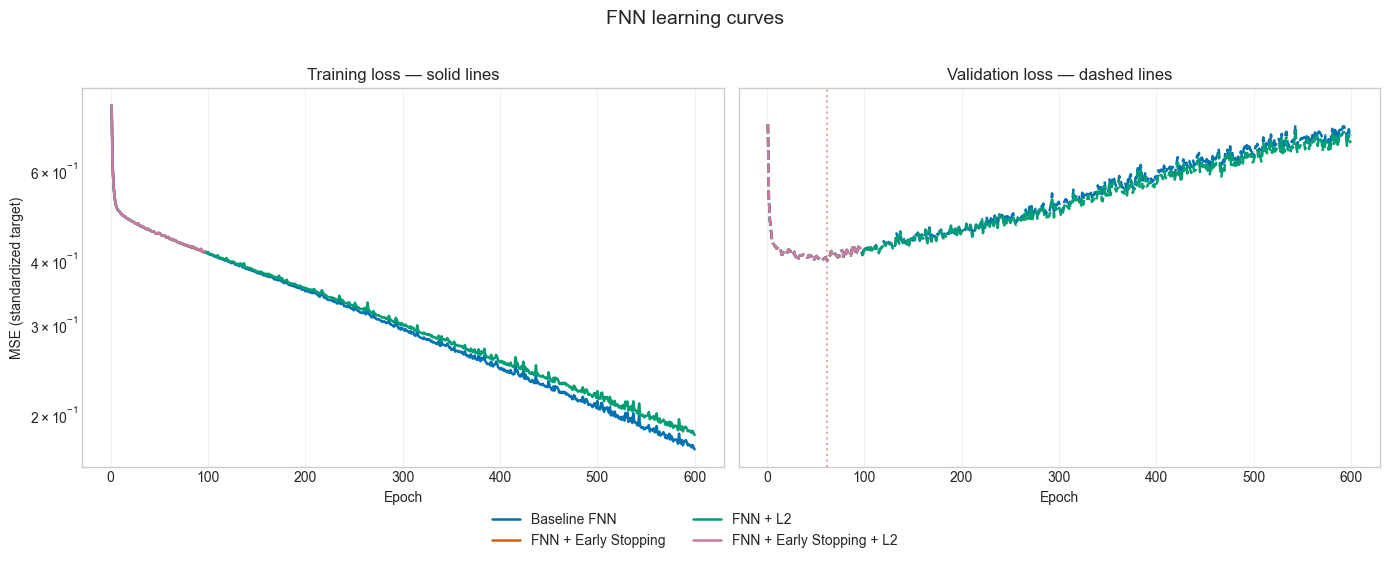

In [4]:
plt.style.use('seaborn-v0_8-whitegrid')
fig,axs=plt.subplots(1,2,figsize=(14,5),sharey=True)
for name,r in runs.items():
    h=r['history']; e=np.arange(1,len(h['train'])+1)
    axs[0].plot(e,h['train'],color=colors[name],label=name,linewidth=1.8)
    axs[1].plot(e,h['val'],color=colors[name],label=name,linewidth=1.8,linestyle='--')
    if configs[name][0]: axs[1].axvline(r['best_epoch'],color=colors[name],alpha=.35,linestyle=':')
for ax,title in zip(axs,['Training loss — solid lines','Validation loss — dashed lines']):
    ax.set(title=title,xlabel='Epoch',yscale='log'); ax.grid(True,which='major',alpha=.25)
axs[0].set_ylabel('MSE (standardized target)')
fig.legend(*axs[0].get_legend_handles_labels(),loc='lower center',ncol=2,frameon=False,bbox_to_anchor=(.5,-.08))
fig.suptitle('FNN learning curves',y=1.02,fontsize=14); fig.tight_layout(); plt.show()

### Held-out test evaluation

Test metrics are computed only after fitting and validation-based checkpoint selection. MSE, RMSE, and MAE are in original target units; lower is better. The test set does not influence training, early stopping, or configuration selection.

,Test MSE,Test RMSE,Test MAE,Epochs trained,Selected epoch
Configuration,,,,,
Baseline FNN,5214.291,72.210,54.591,600,600
FNN + Early Stopping,2864.687,53.523,41.883,97,62
FNN + L2,4967.460,70.480,53.305,600,600
FNN + Early Stopping + L2,2861.492,53.493,41.864,97,62


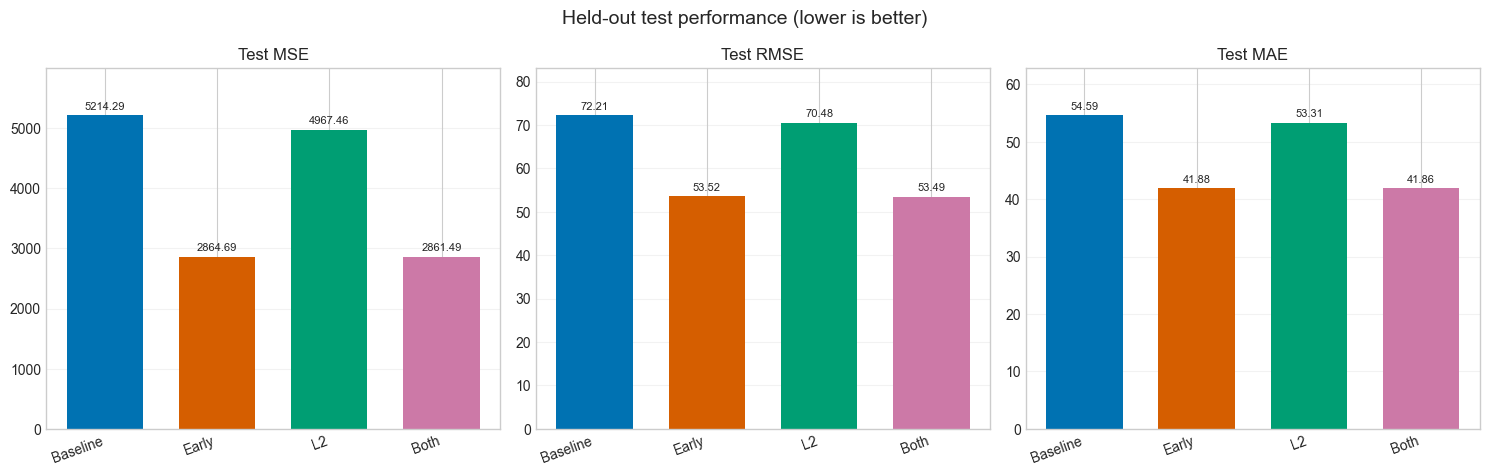

In [5]:
rows=[]
for name,r in runs.items():
    pred=ys.inverse_transform(forward(Xte,r['params'])[0][-1]).ravel(); actual=yte0.ravel()
    mse=mean_squared_error(actual,pred)
    rows.append({'Configuration':name,'Test MSE':mse,'Test RMSE':np.sqrt(mse),'Test MAE':mean_absolute_error(actual,pred),'Epochs trained':r['trained'],'Selected epoch':r['best_epoch']})
metrics=pd.DataFrame(rows).set_index('Configuration'); display(metrics.round(3))
fig,axs=plt.subplots(1,3,figsize=(15,4.8))
for ax,m in zip(axs,['Test MSE','Test RMSE','Test MAE']):
    vals=metrics.loc[list(configs),m]; bars=ax.bar(range(len(vals)),vals.to_numpy(),color=[colors[n] for n in vals.index],width=.68)
    ax.set_title(m); ax.set_xticks(range(4),['Baseline','Early','L2','Both'],rotation=20,ha='right'); ax.grid(axis='y',alpha=.25); ax.bar_label(bars,fmt='%.2f',padding=3,fontsize=8); ax.margins(y=.15)
fig.suptitle('Held-out test performance (lower is better)',fontsize=14); fig.tight_layout(); plt.show()

### Results-based analysis

The following cell prints observed train/validation gaps and the best test-MAE configuration. Use those measurements with the curves and metric table to complete the group's analysis. A widening gap while training MSE falls can indicate overfitting; Early Stopping limits training based on validation performance, while L2 discourages large weights and may reduce variance at the cost of some bias. Neither technique is guaranteed to improve every metric on every split—describe what the measured results show, not an expected outcome.

**Conclusion template:** identify which configuration showed the largest train–validation gap; state the epochs trained and checkpoint epoch for Early Stopping runs; compare the four test MSE/RMSE/MAE values; conclude whether either or both regularization methods improved generalization on this split. This is a single split and fixed hyperparameter setup, so results may vary with random seed or tuning; repeated seeds/cross-validation would provide stronger evidence.

In [6]:
print('Lowest held-out test MAE:',metrics['Test MAE'].idxmin(),f"({metrics['Test MAE'].min():.3f})")
for name,r in runs.items():
    h=r['history']; tr,va=h['train'][-1],h['val'][-1]
    print(f"{name}: final train MSE={tr:.4f}, final validation MSE={va:.4f}, minimum validation MSE={min(h['val']):.4f}, val-train gap={va-tr:.4f}, epochs={r['trained']}, selected epoch={r['best_epoch']}")

Lowest held-out test MAE: FNN + Early Stopping + L2 (41.864)
Baseline FNN: final train MSE=0.1712, final validation MSE=0.7070, minimum validation MSE=0.4005, val-train gap=0.5358, epochs=600, selected epoch=600
FNN + Early Stopping: final train MSE=0.4167, final validation MSE=0.4203, minimum validation MSE=0.4005, val-train gap=0.0037, epochs=97, selected epoch=62
FNN + L2: final train MSE=0.1827, final validation MSE=0.6887, minimum validation MSE=0.4004, val-train gap=0.5060, epochs=600, selected epoch=600
FNN + Early Stopping + L2: final train MSE=0.4179, final validation MSE=0.4197, minimum validation MSE=0.4004, val-train gap=0.0018, epochs=97, selected epoch=62


## Tài liệu tham khảo & Nguồn dữ liệu (References & Dataset)

### 1. Nguồn dữ liệu (Dataset Source)
* **Tên tập dữ liệu:** Diabetes Dataset (Tập dữ liệu bệnh tiểu đường).
* **Nguồn gốc:** Được tích hợp sẵn trong thư viện `scikit-learn` thông qua hàm `sklearn.datasets.load_diabetes`.
* **Xuất bản gốc:** Efron, Hastie, Johnstone and Tibshirani (2004), *"Least Angle Regression"*, Annals of Statistics, 32(2), 407-499.
* **Thông tin thuộc tính:** Gồm 442 mẫu bệnh nhân với 10 thuộc tính đặc trưng (features) ban đầu (như tuổi, giới tính, BMI, huyết áp trung bình và 6 chỉ số đo huyết thanh) và một biến mục tiêu (target) định lượng biểu thị mức độ tiến triển của bệnh sau một năm.

### 2. Tài liệu tham khảo học thuật (Academic References)
* **Giáo trình chính:** Slide bài giảng môn Học máy (Machine Learning) - Khoa Công nghệ thông tin, Trường Đại học Tôn Đức Thắng (TDTU).
* **Tài liệu tham khảo thêm:**
  * Goodfellow, I., Bengio, Y., & Courville, A. (2016). *Deep Learning*. MIT Press. (Chương 7: Regularization for Deep Learning).
  * Bishop, C. M. (2006). *Pattern Recognition and Machine Learning*. Springer. (Chương 5: Neural Networks).
  * Scikit-learn Documentation: [https://scikit-learn.org/stable/modules/classes.html](https://scikit-learn.org/stable/modules/classes.html)